In [1]:
import sys
import os
sys.path.append(os.path.abspath("../src")) # Permite importar nba_classifier

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from nba_classifier.data.ingestion import load_seasons
from nba_classifier.preprocessing.cleaning import clean_season_df, build_target, drop_leaky_columns

# Configuración de gráficas
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
# Cargar y limpiar datos
df_raw = load_seasons(list(range(2015, 2027)))
df_clean = clean_season_df(df_raw, min_games=20)
df_clean = build_target(df_clean)
df_clean = drop_leaky_columns(df_clean)

print(f"Dimensiones: {df_clean.shape}")
df_clean.head()

Dimensiones: (5163, 47)


,season,player_id,age,team,pos,games,games_started,mp,fg,fga,...,drb_pct,trb_pct,ast_pct,stl_pct,blk_pct,tov_pct,usg_pct,kind_adv,is_aggregated,y
0,2015,acyqu01,24.0,NYK,Unknown,68.0,22.0,1287.0,152.0,331.0,...,20.5,13.5,8.7,1.1,1.4,13.8,15.5,advanced,False,0
1,2015,adamsjo01,20.0,MEM,Unknown,30.0,0.0,248.0,35.0,86.0,...,8.7,6.4,10.1,3.4,2.3,12.7,20.4,advanced,False,0
2,2015,adamsst01,21.0,OKC,Unknown,70.0,67.0,1771.0,217.0,399.0,...,19.3,15.8,5.5,1.1,3.8,16.8,14.3,advanced,False,0
4,2015,afflaar01,29.0,2TM,Unknown,78.0,72.0,2502.0,375.0,884.0,...,9.7,5.3,8.2,0.8,0.2,10.7,19.0,advanced,True,0
5,2015,ajincal01,26.0,NOP,Unknown,68.0,8.0,957.0,181.0,329.0,...,25.0,18.7,8.2,1.2,4.0,15.6,21.1,advanced,False,0


/tmp/ipykernel_11962/750441318.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='y', palette='Set2')


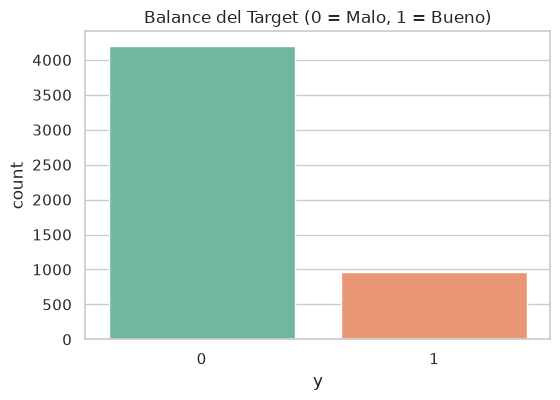

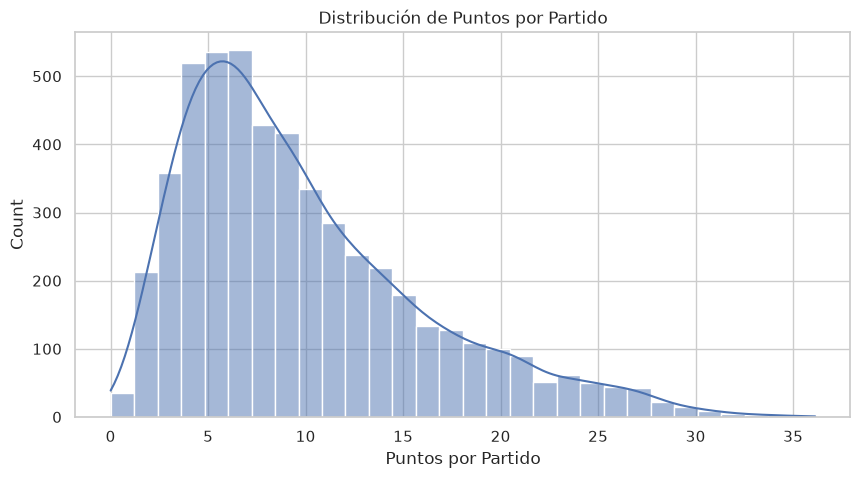

In [3]:
# Balance del Target
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='y', palette='Set2')
plt.title('Balance del Target (0 = Malo, 1 = Bueno)')
plt.show()

# Histograma de Puntos por partido
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['pts'] / df_clean['games'], bins=30, kde=True)
plt.title('Distribución de Puntos por Partido')
plt.xlabel('Puntos por Partido')
plt.show()

/tmp/ipykernel_11962/1768388080.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = df_clean.select_dtypes(include=['object', 'category']).columns


Variables numéricas encontradas: 39
Variables categóricas encontradas: 6


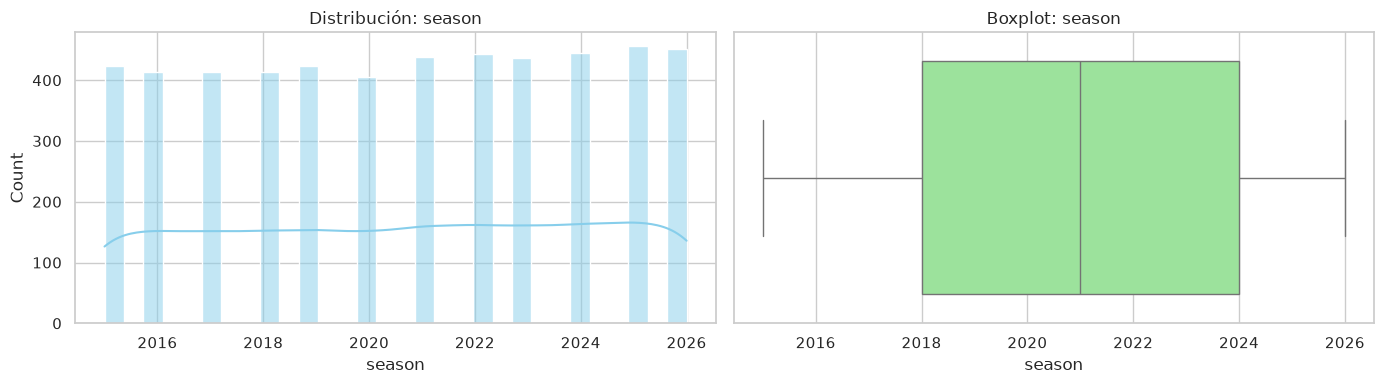

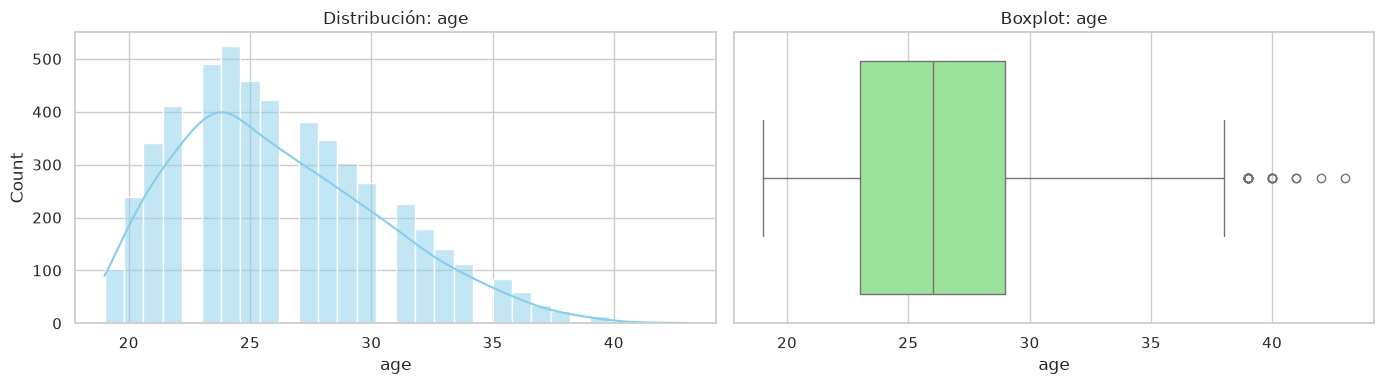

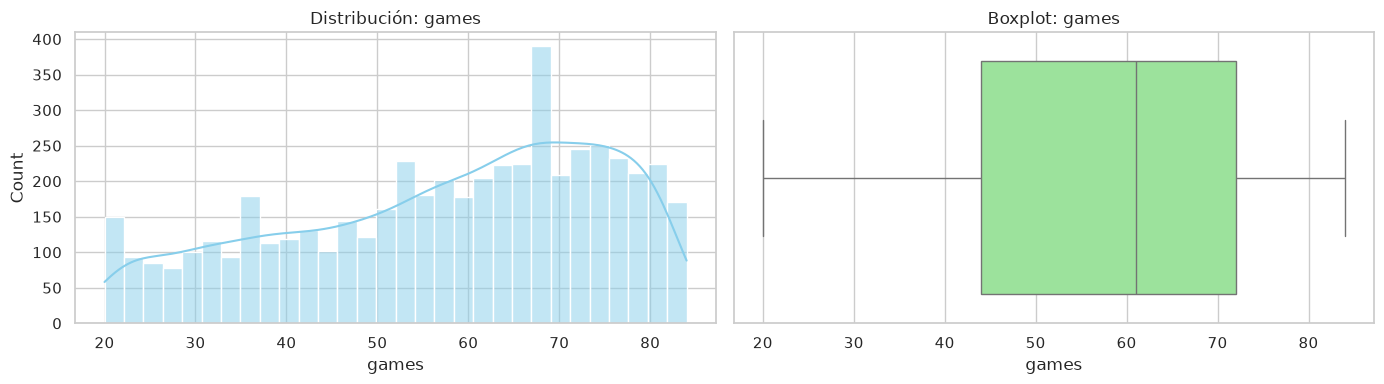

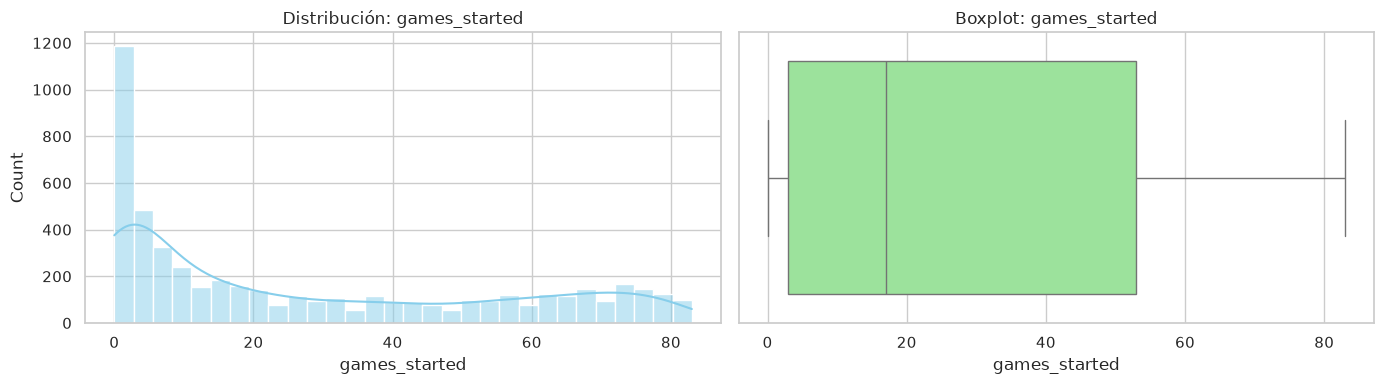

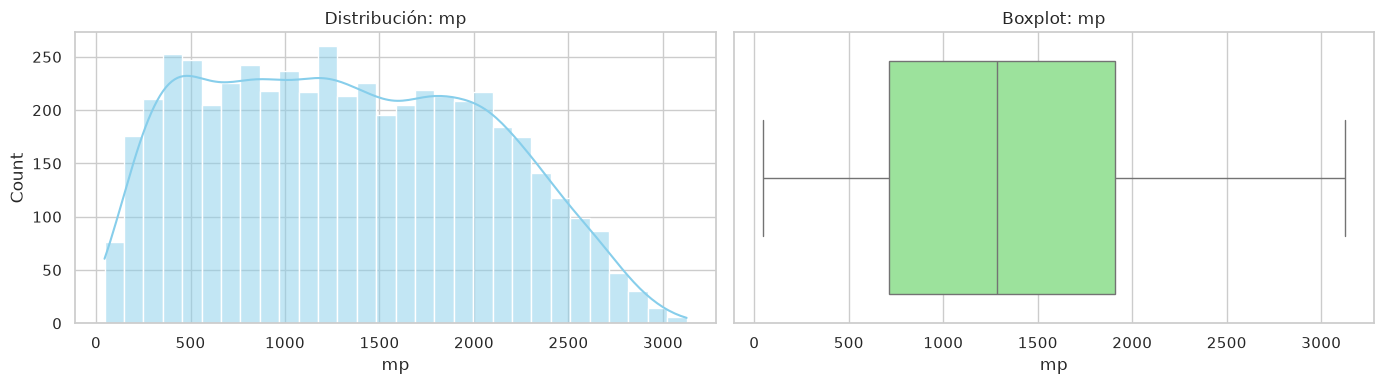

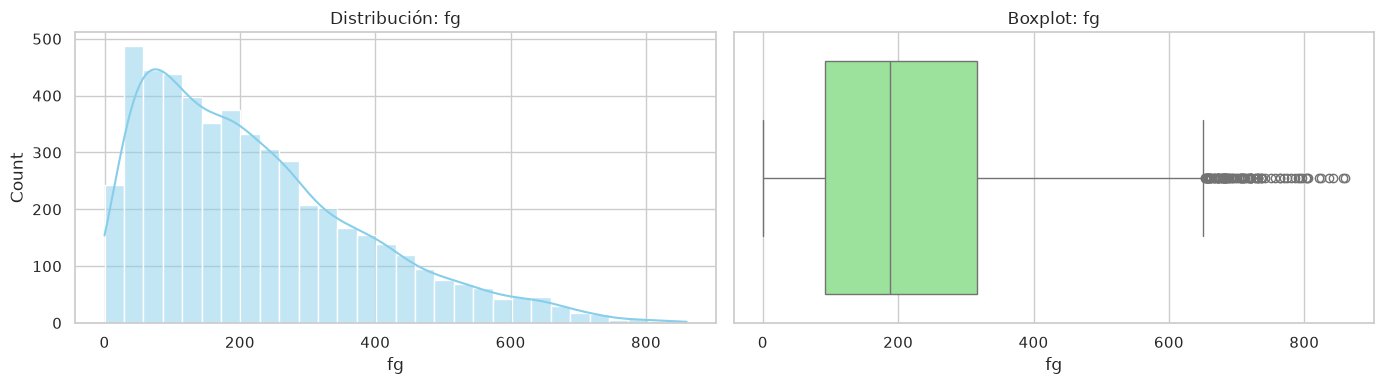

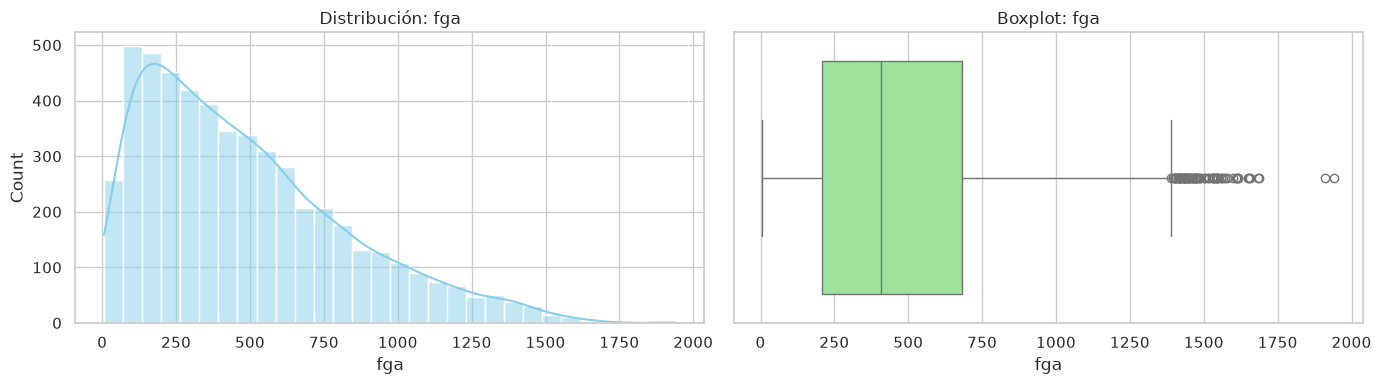

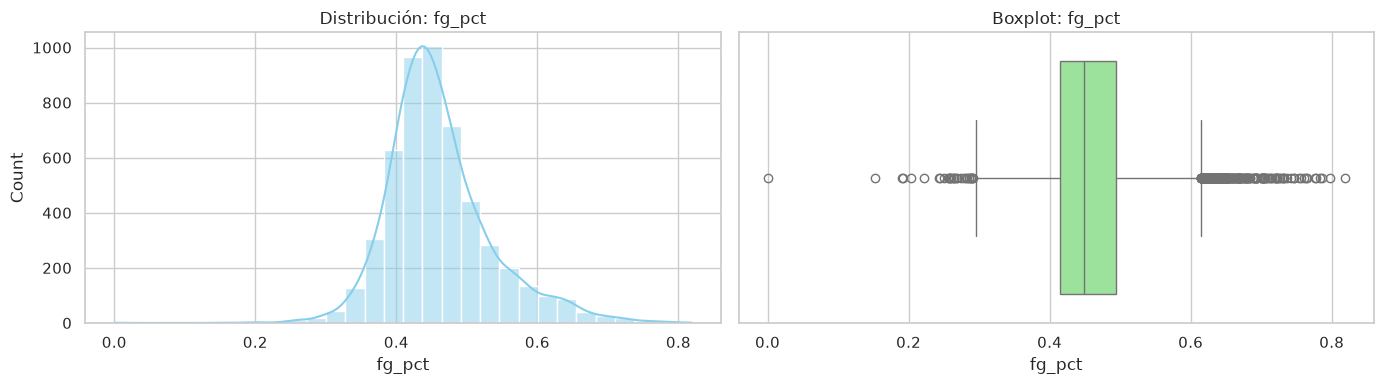

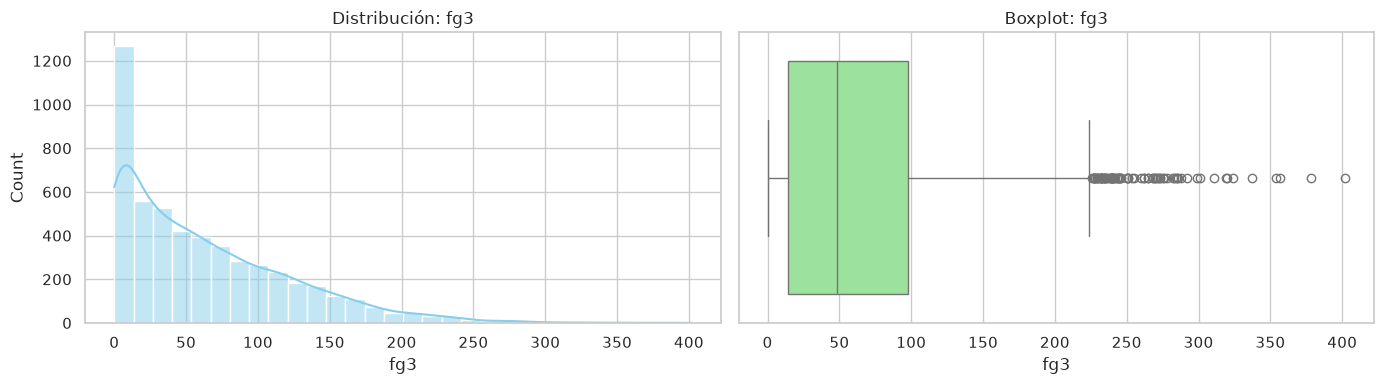

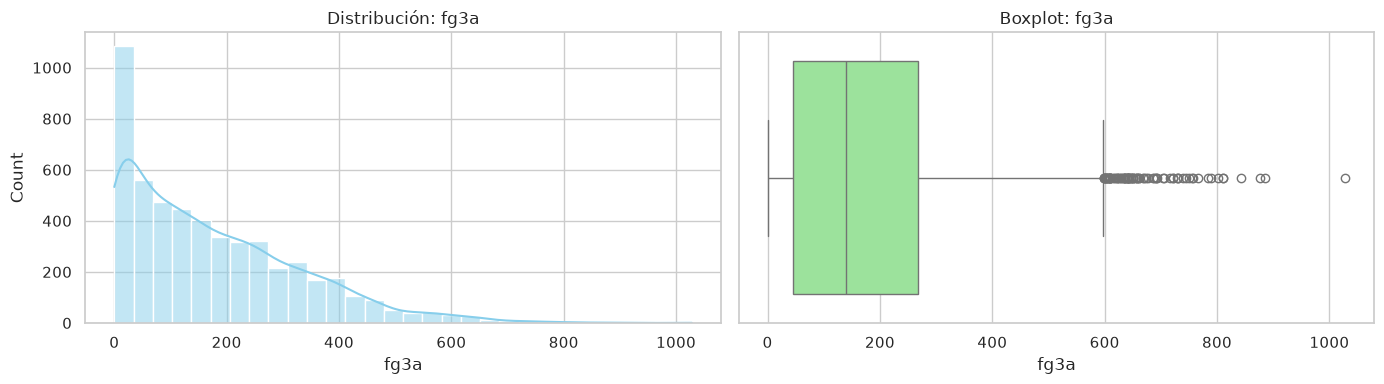

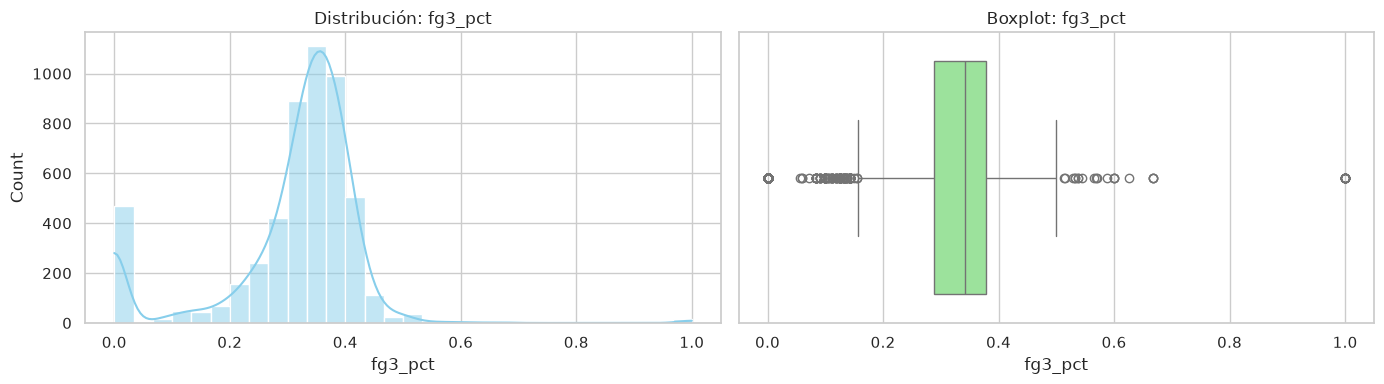

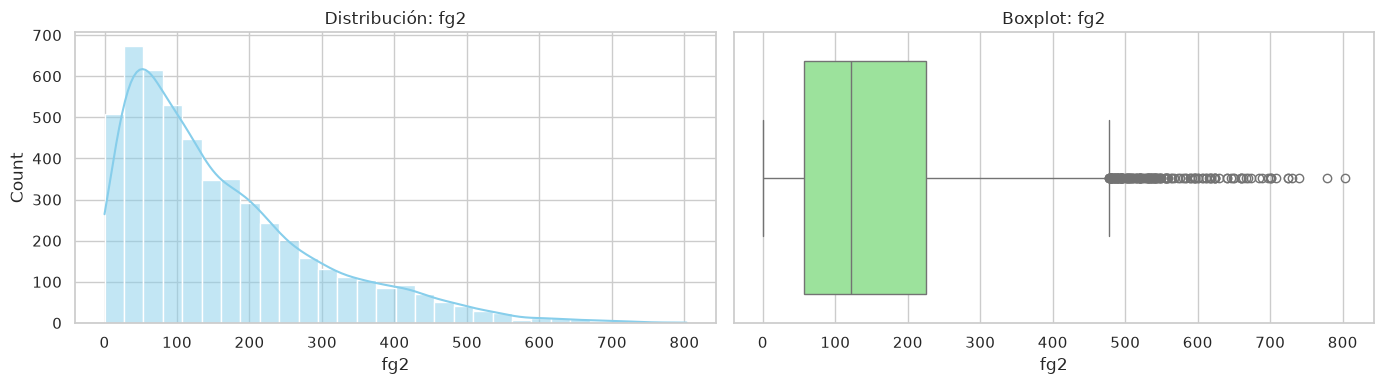

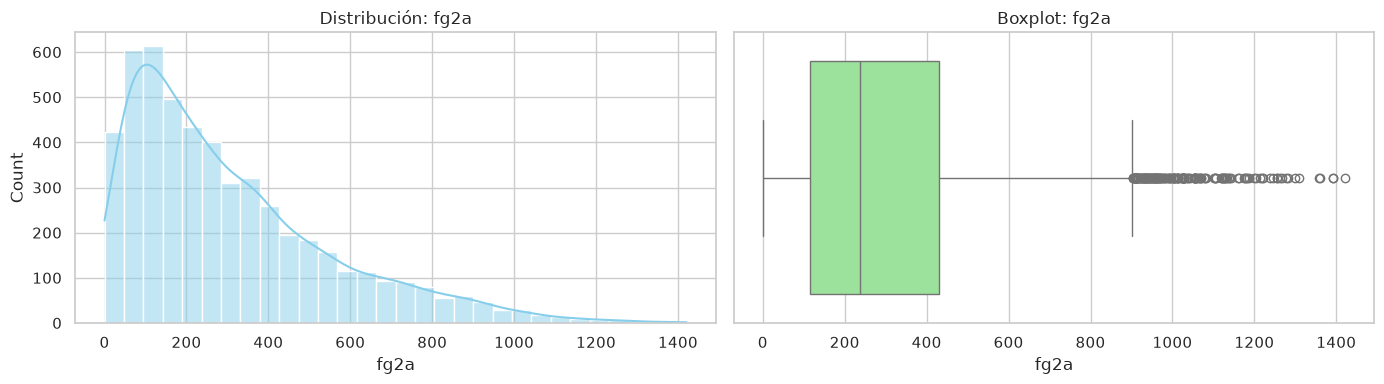

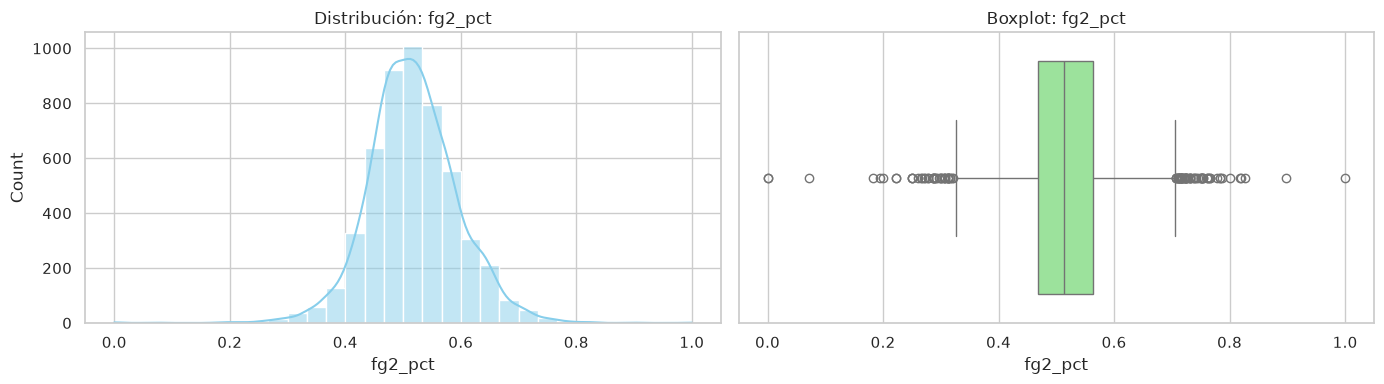

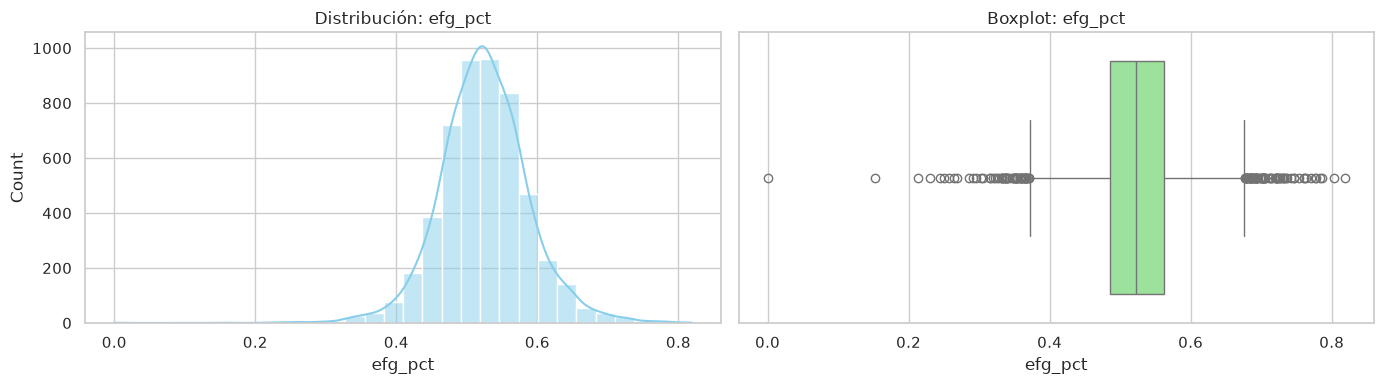

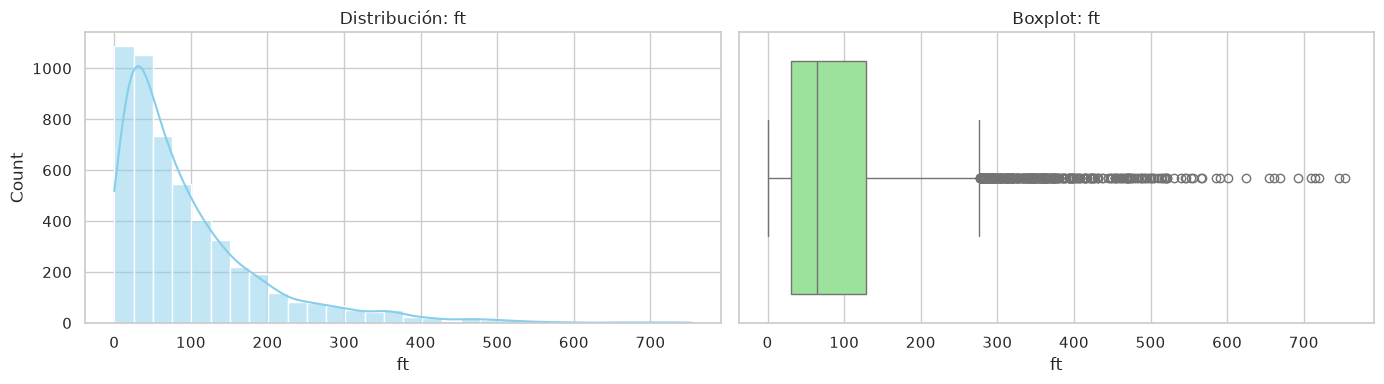

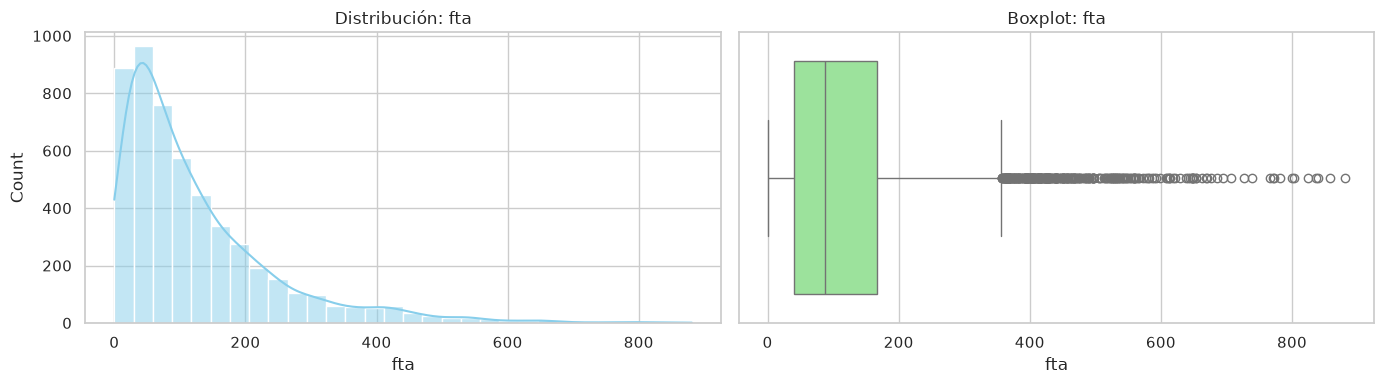

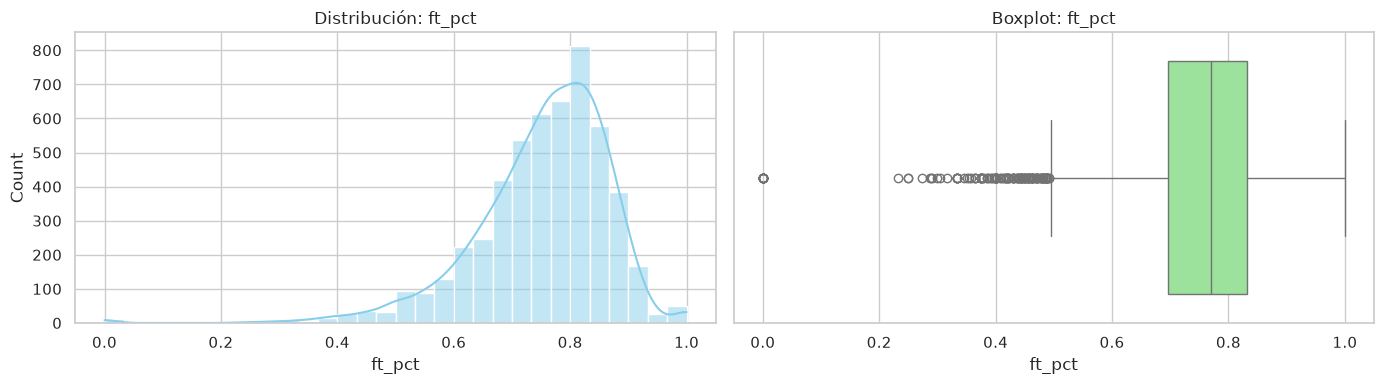

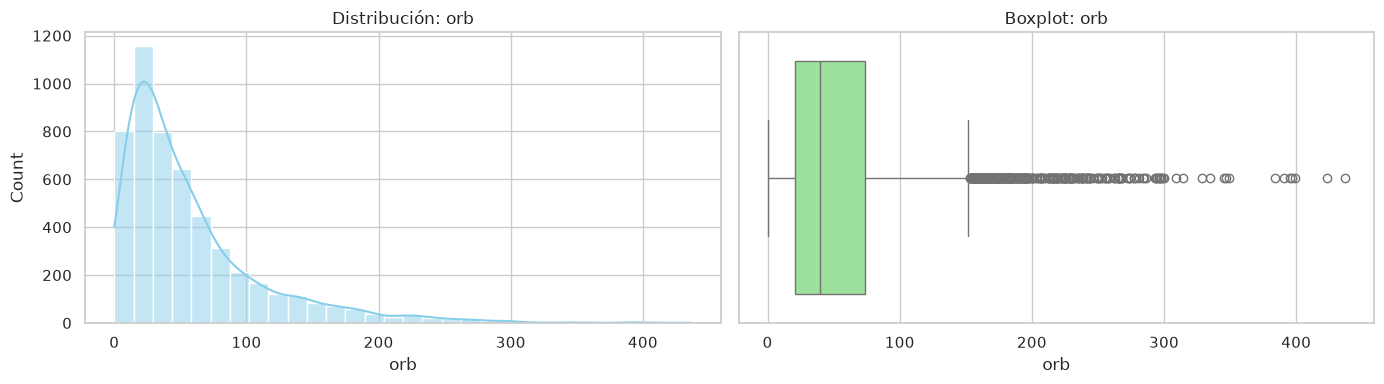

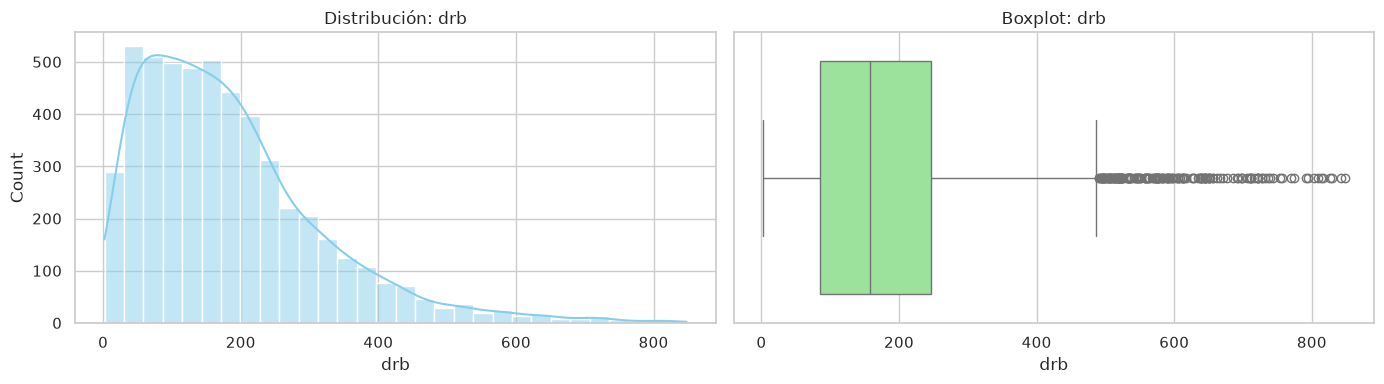

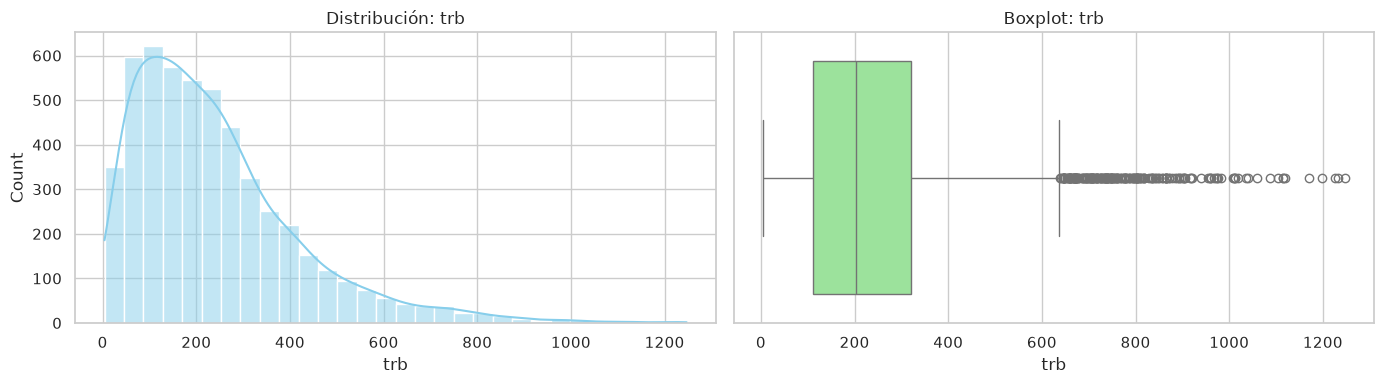

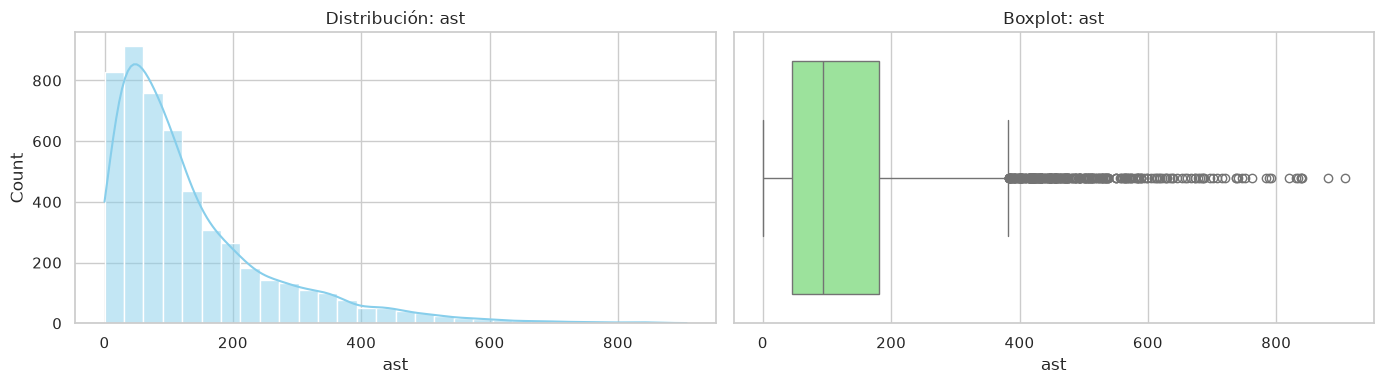

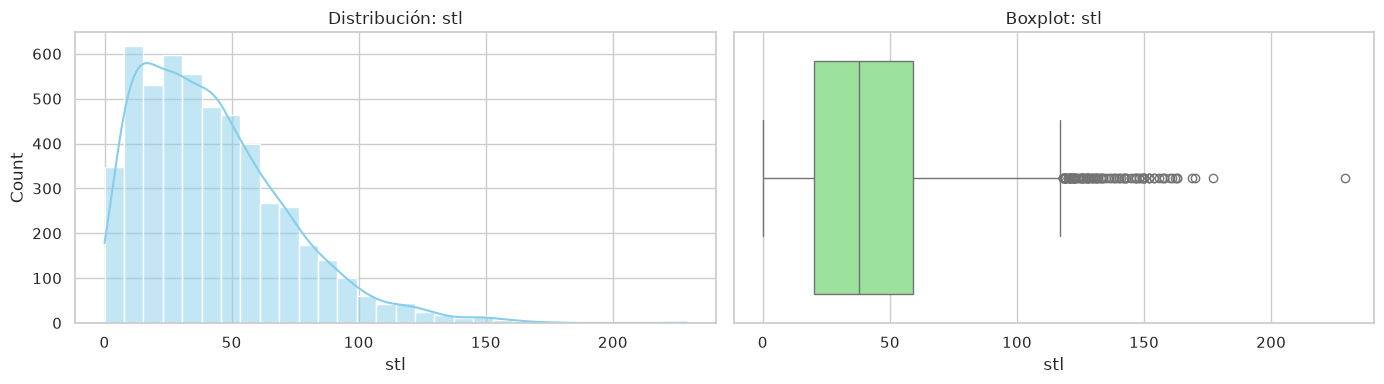

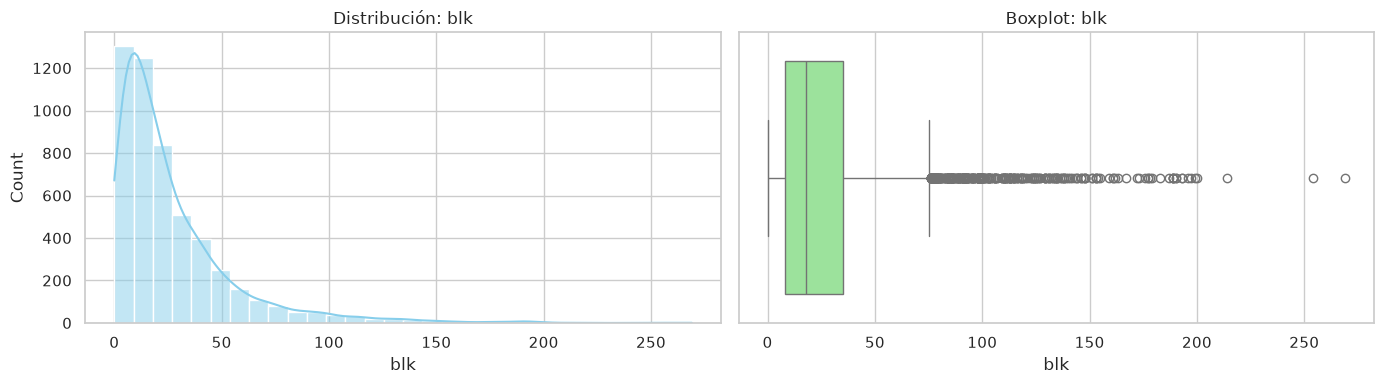

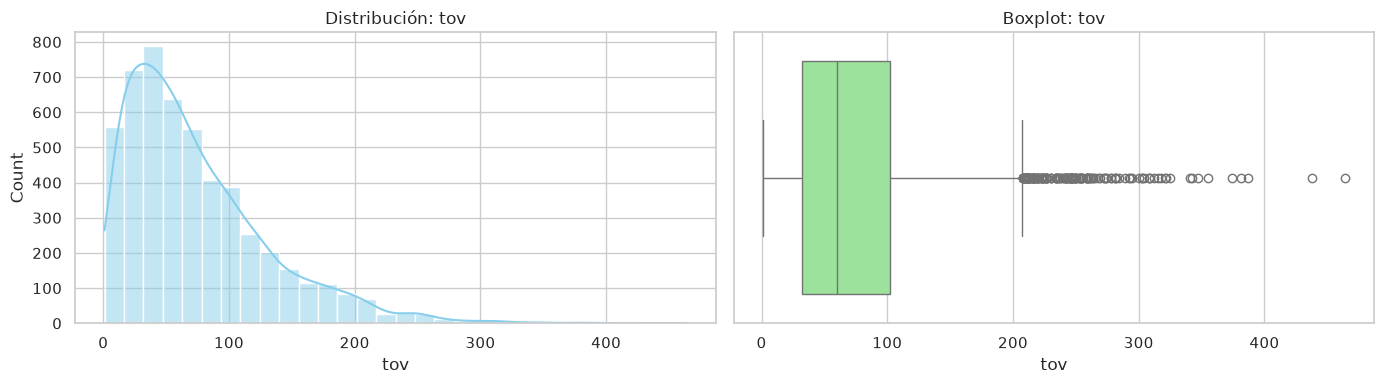

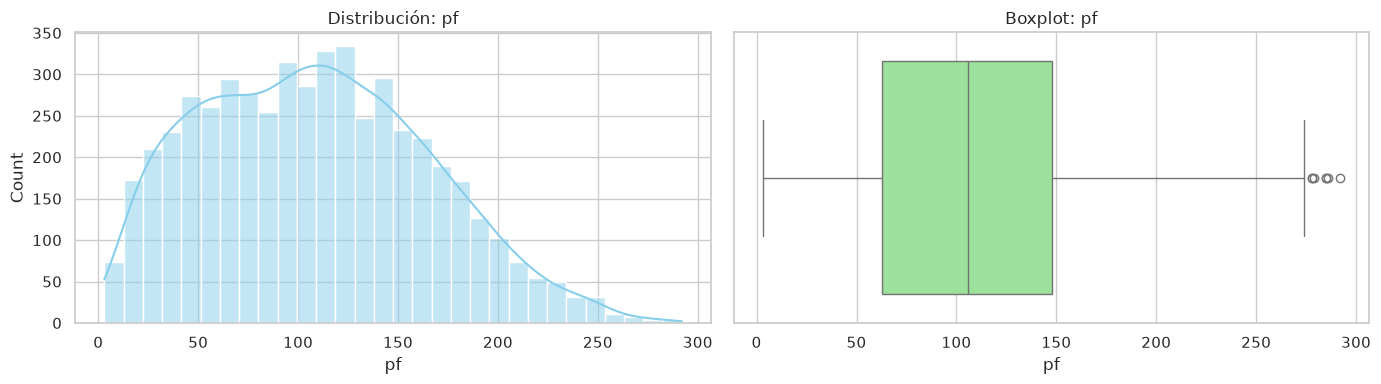

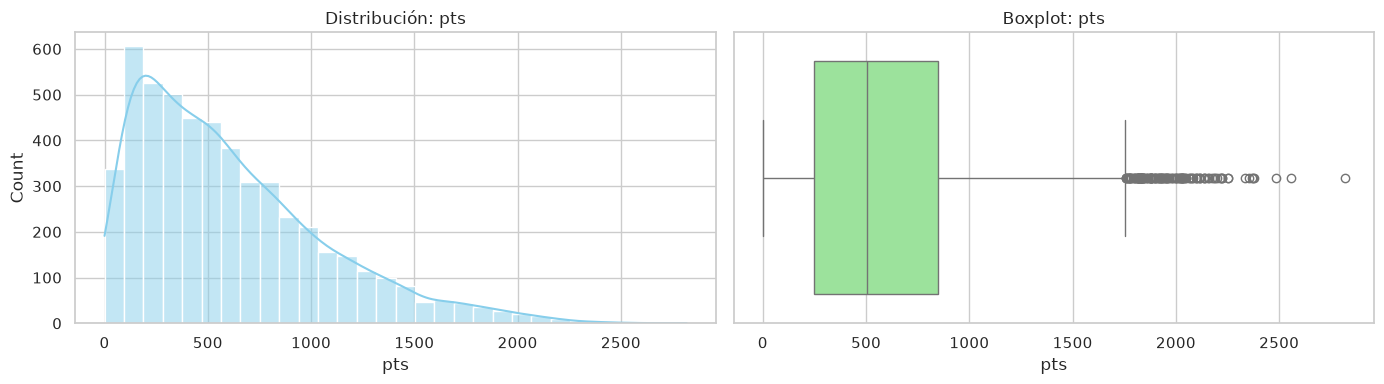

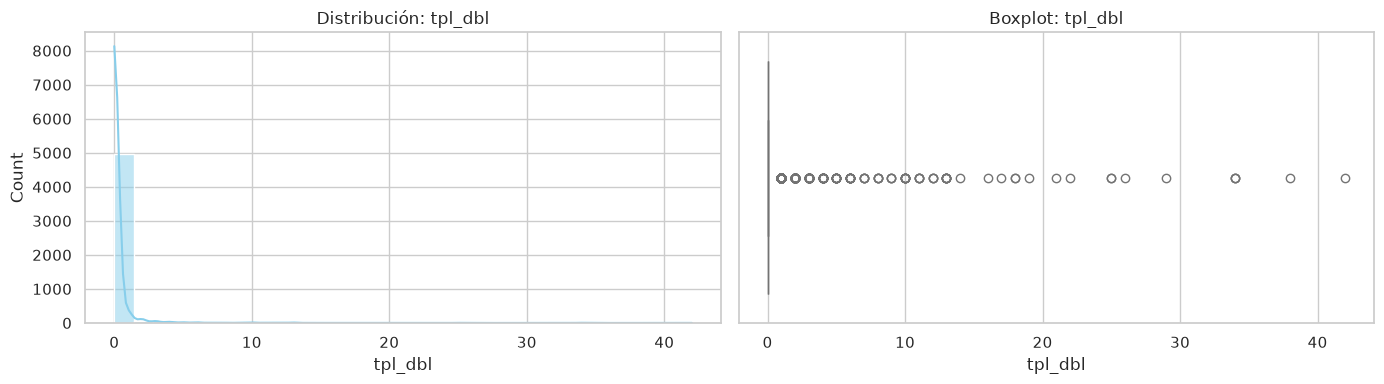

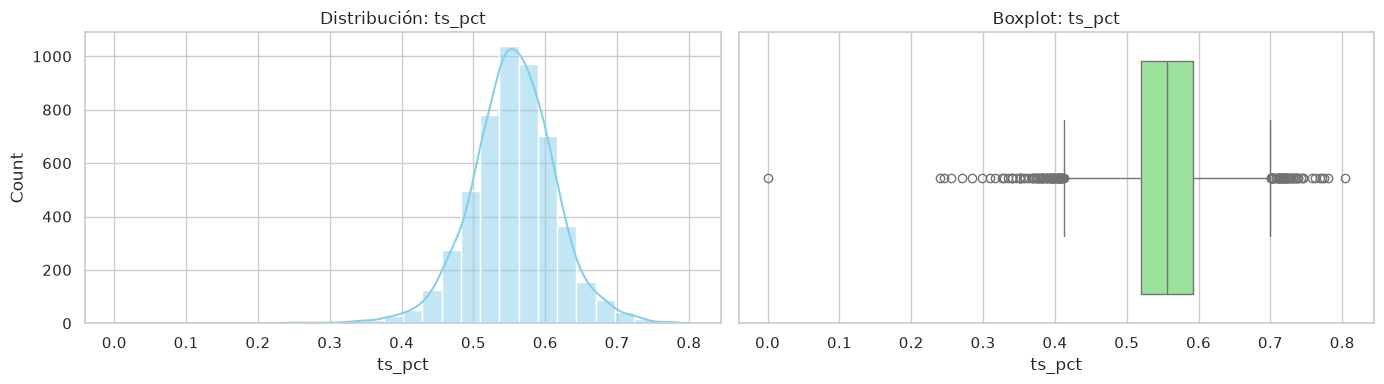

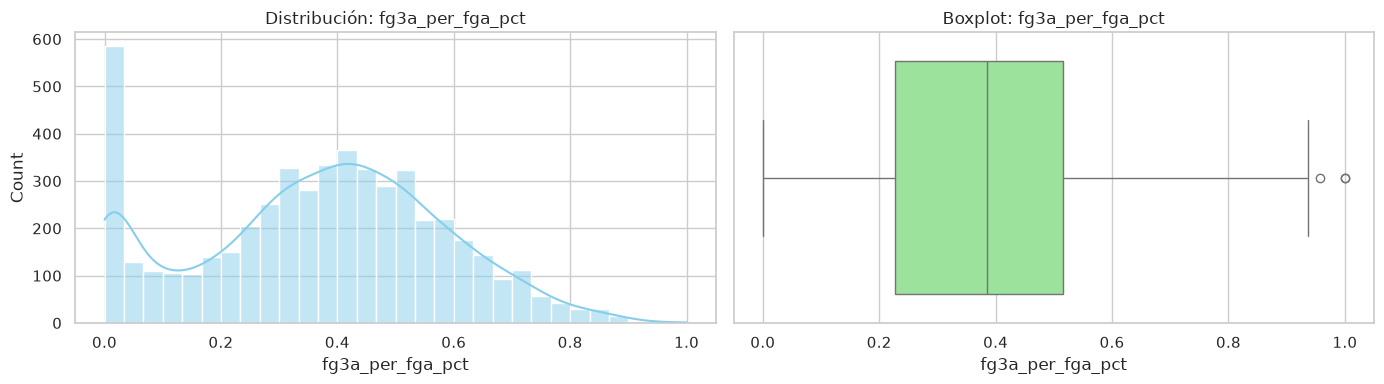

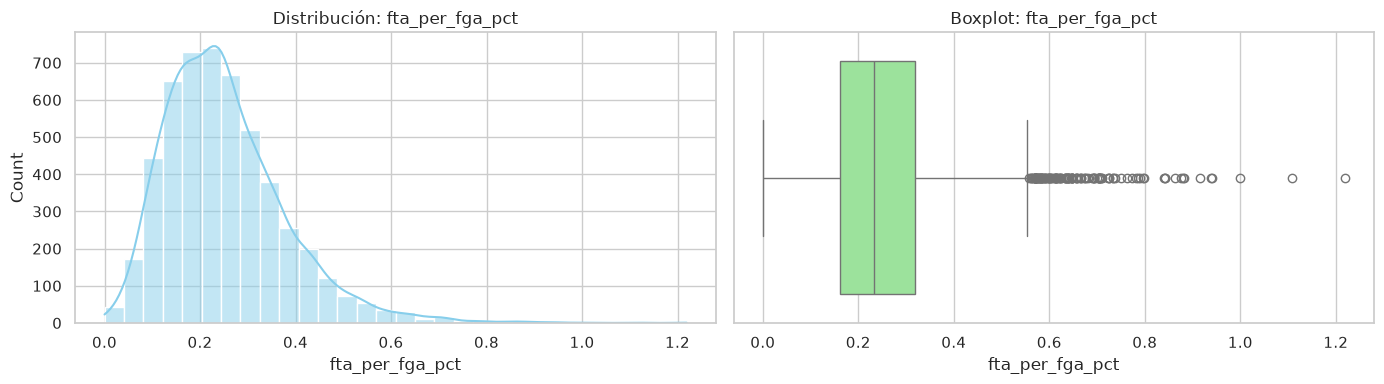

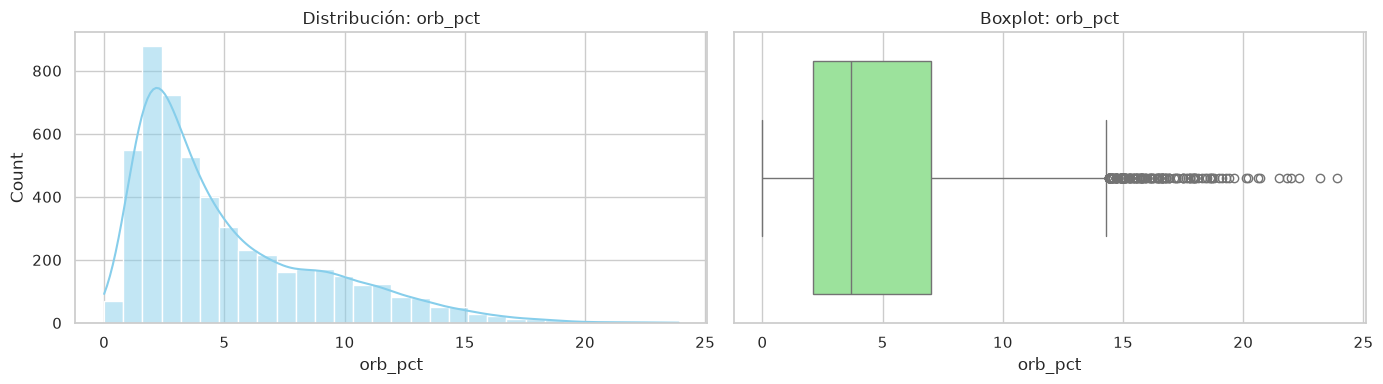

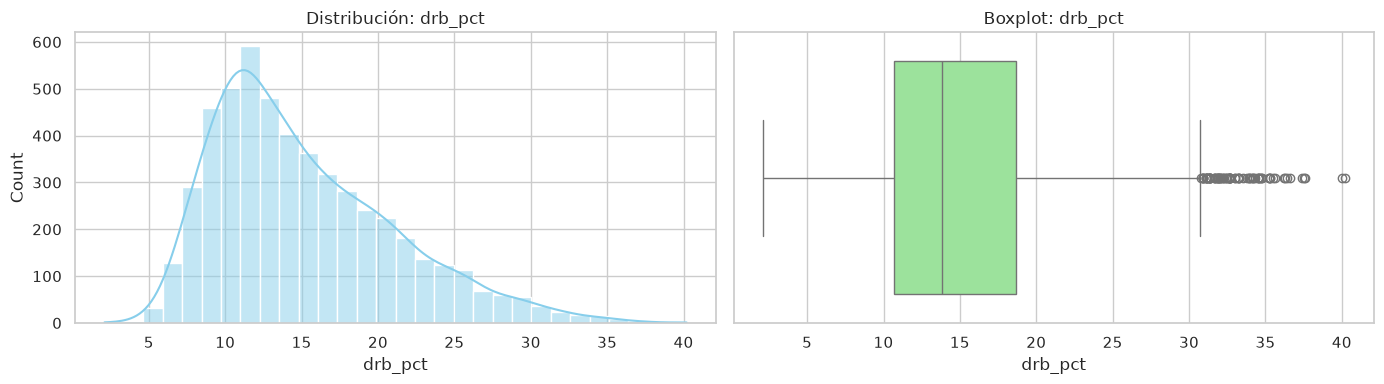

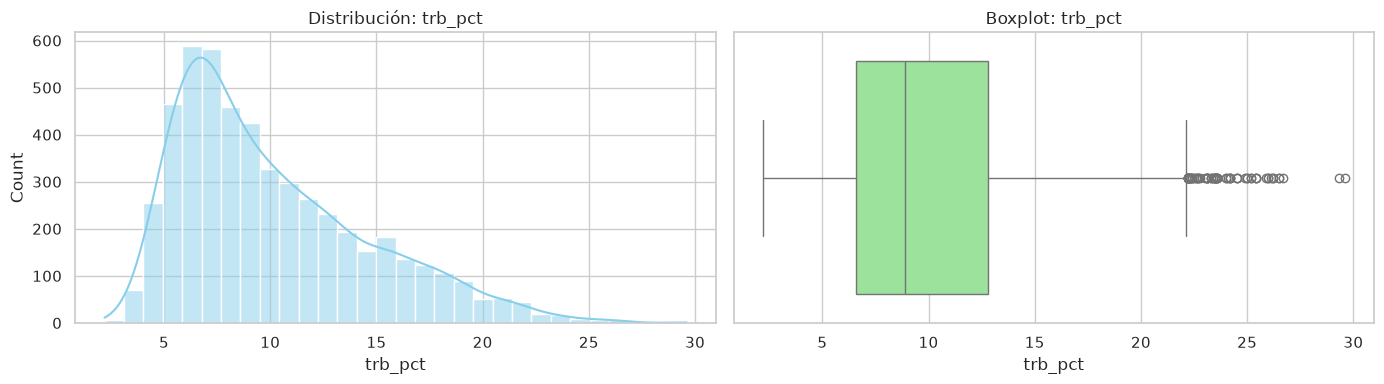

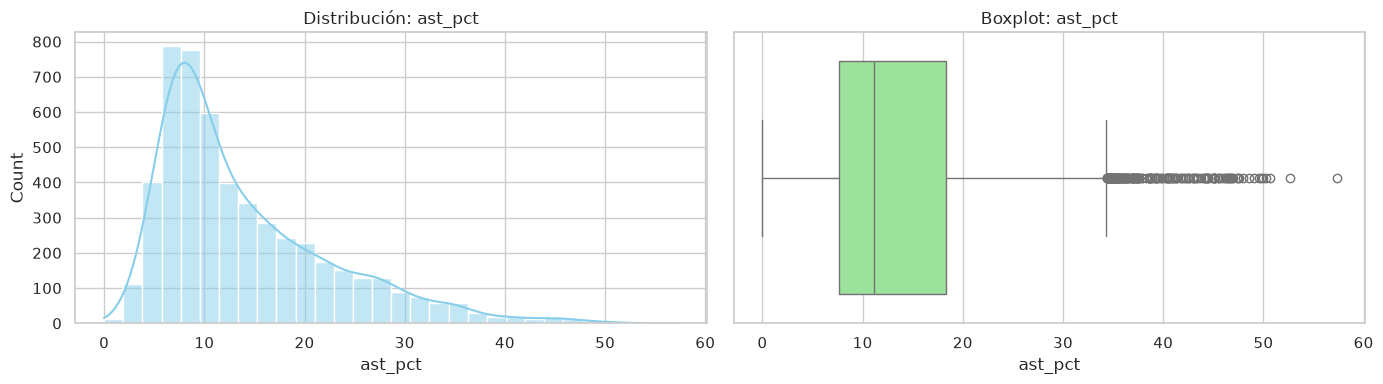

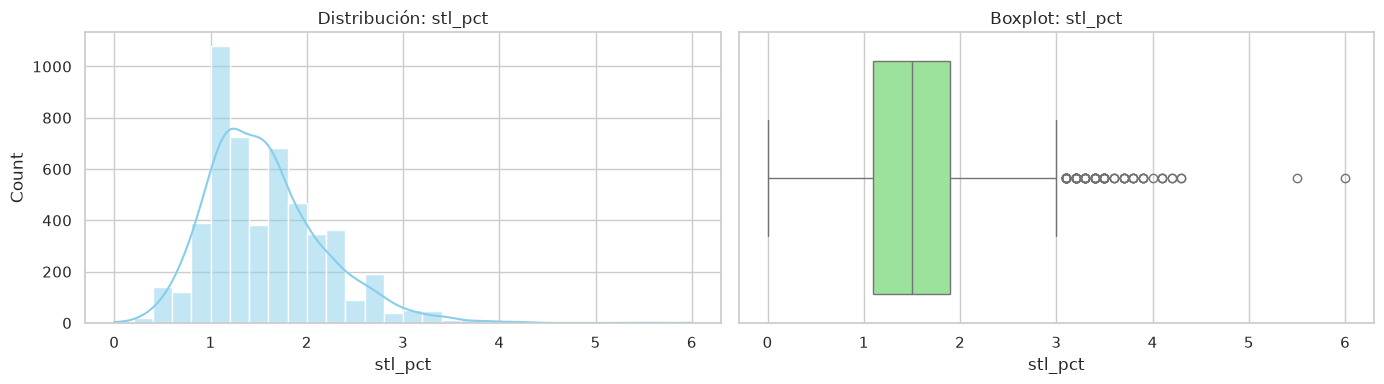

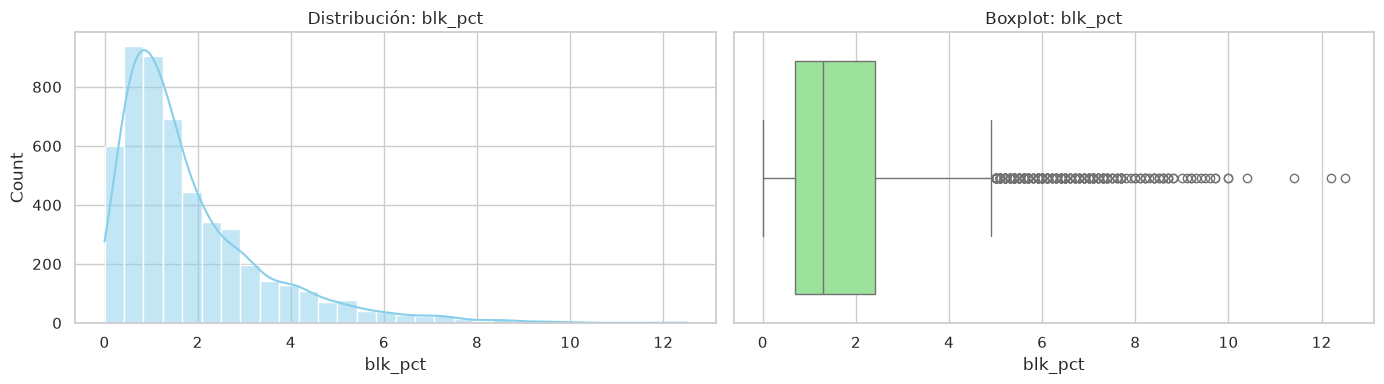

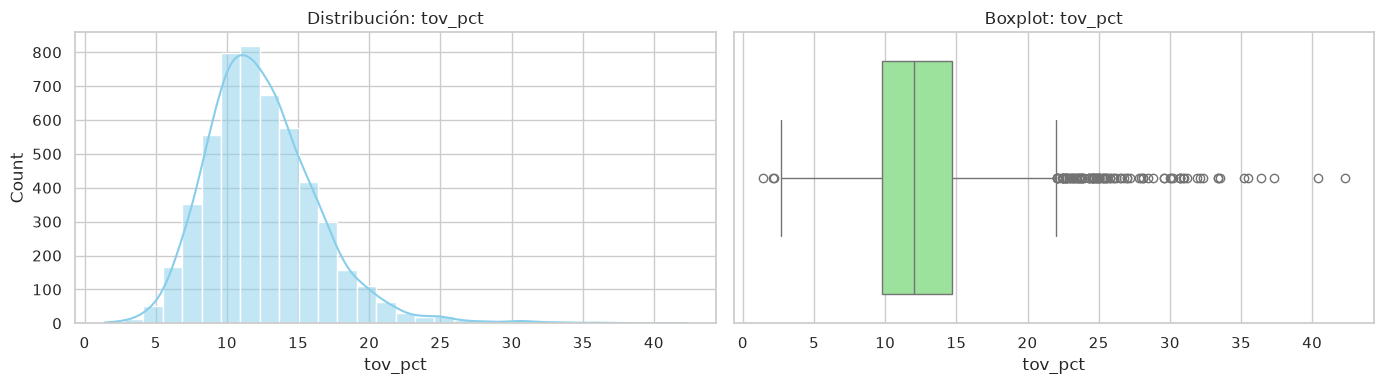

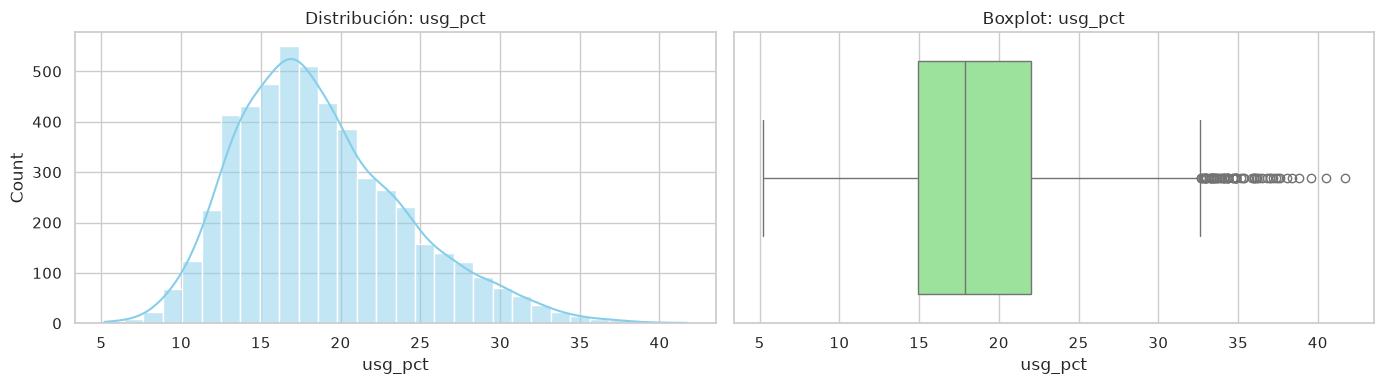

/tmp/ipykernel_11962/1768388080.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean[df_clean[col].isin(top_clases)], y=col, palette='viridis')


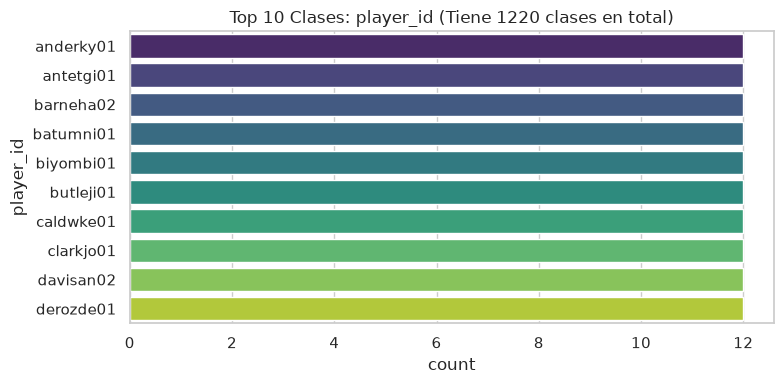

/tmp/ipykernel_11962/1768388080.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean[df_clean[col].isin(top_clases)], y=col, palette='viridis')


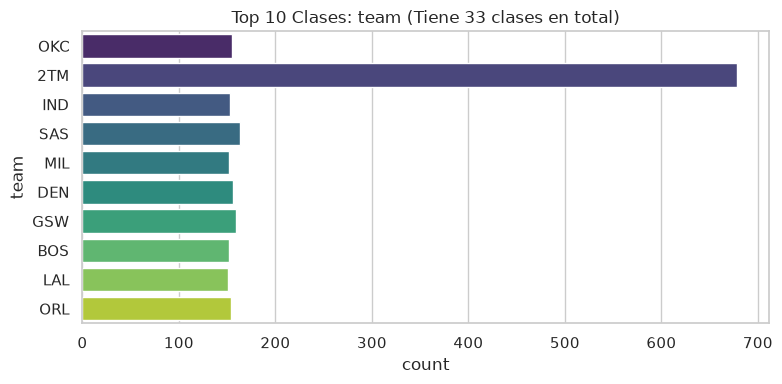

/tmp/ipykernel_11962/1768388080.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x=col, palette='viridis')


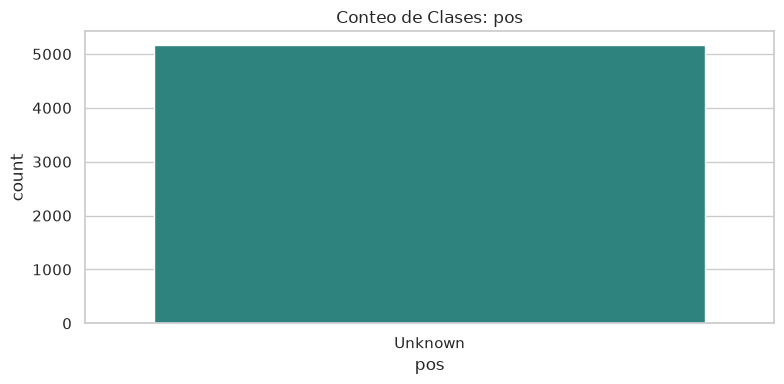

/tmp/ipykernel_11962/1768388080.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x=col, palette='viridis')


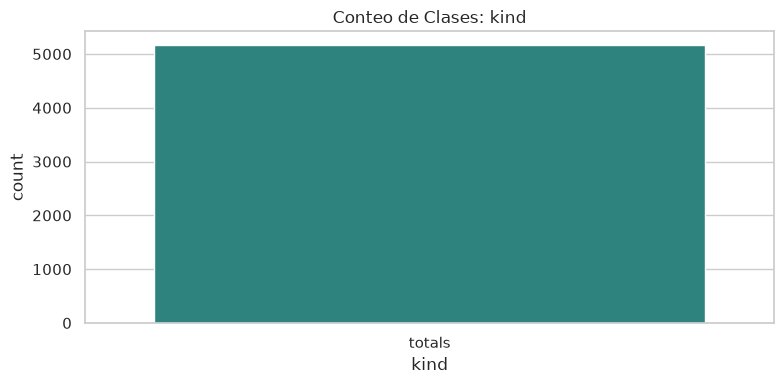

/tmp/ipykernel_11962/1768388080.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean[df_clean[col].isin(top_clases)], y=col, palette='viridis')


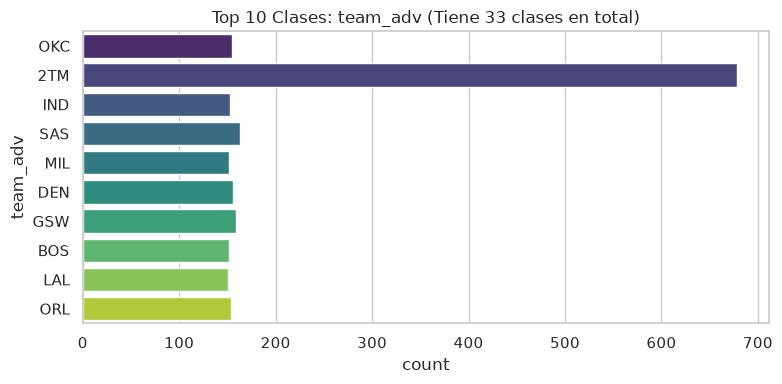

/tmp/ipykernel_11962/1768388080.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x=col, palette='viridis')


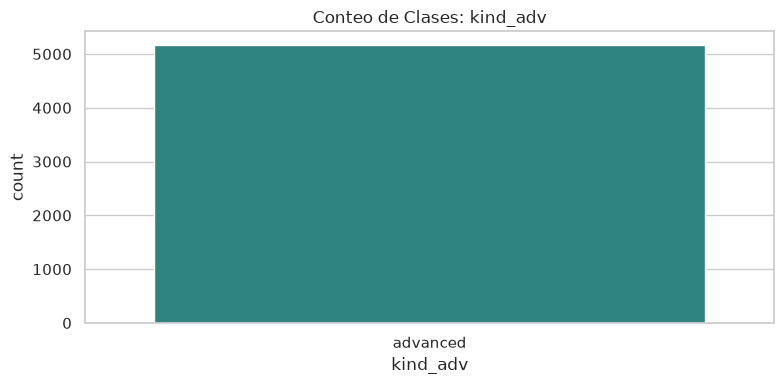


--- Estadísticas Descriptivas de Variables Numéricas ---


,count,mean,std,min,25%,50%,75%,max
season,5163.0,2020.608948,3.465876,2015.0,2018.0000,2021.000,2024.000,2026.000
age,5163.0,26.188263,4.287810,19.0,23.0000,26.000,29.000,43.000
games,5163.0,57.295952,17.360089,20.0,44.0000,61.000,72.000,84.000
games_started,5163.0,27.762154,27.356366,0.0,3.0000,17.000,53.000,83.000
mp,5163.0,1327.066047,721.374929,45.0,712.0000,1286.000,1908.500,3125.000
fg,5163.0,223.221770,163.190286,0.0,92.0000,188.000,316.000,860.000
fga,5163.0,481.408096,342.490930,6.0,208.0000,409.000,680.500,1941.000
fg_pct,5163.0,0.460333,0.074005,0.0,0.4140,0.449,0.494,0.819
fg3,5163.0,62.917296,59.414220,0.0,14.0000,48.000,98.000,402.000
fg3a,5163.0,174.884563,154.833488,0.0,46.0000,139.000,267.000,1028.000


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Estilo de las gráficas
sns.set_theme(style="whitegrid")

# 1. Separar automáticamente las columnas numéricas y categóricas
# Excluimos la columna 'y' (target) y variables de texto que no nos sirvan (como nombres)
columnas_numericas = df_clean.select_dtypes(include=['float64', 'int64']).columns.drop('y', errors='ignore')
columnas_categoricas = df_clean.select_dtypes(include=['object', 'category']).columns

print(f"Variables numéricas encontradas: {len(columnas_numericas)}")
print(f"Variables categóricas encontradas: {len(columnas_categoricas)}")

# 2. Análisis de Variables Numéricas (Histogramas y Boxplots)
# Creamos un bucle para graficar cada variable numérica
for col in columnas_numericas:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Histograma con KDE (para ver la distribución)
    sns.histplot(df_clean[col], bins=30, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Distribución: {col}')
    axes[0].set_xlabel(col)
    
    # Boxplot (para ver la escala y los outliers)
    sns.boxplot(x=df_clean[col], ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Boxplot: {col}')
    axes[1].set_xlabel(col)
    
    plt.tight_layout()
    plt.show()

# 3. Análisis de Variables Categóricas (Conteo de clases)
for col in columnas_categoricas:
    plt.figure(figsize=(8, 4))
    # Si una categoría tiene muchas clases únicas, mostramos solo las top 10
    if df_clean[col].nunique() > 15:
        top_clases = df_clean[col].value_counts().nlargest(10).index
        sns.countplot(data=df_clean[df_clean[col].isin(top_clases)], y=col, palette='viridis')
        plt.title(f'Top 10 Clases: {col} (Tiene {df_clean[col].nunique()} clases en total)')
    else:
        sns.countplot(data=df_clean, x=col, palette='viridis')
        plt.title(f'Conteo de Clases: {col}')
    
    plt.tight_layout()
    plt.show()

# 4. Tabla de estadísticas descriptivas para ver escalas
print("\n--- Estadísticas Descriptivas de Variables Numéricas ---")
display(df_clean[columnas_numericas].describe().T)

Top 10 correlaciones con el Target:
y       1.000000
ft      0.521591
fta     0.518716
fg2     0.497976
pts     0.495762
fg      0.490163
fg2a    0.464130
drb     0.447942
ast     0.440352
fga     0.436515
Name: y, dtype: float64


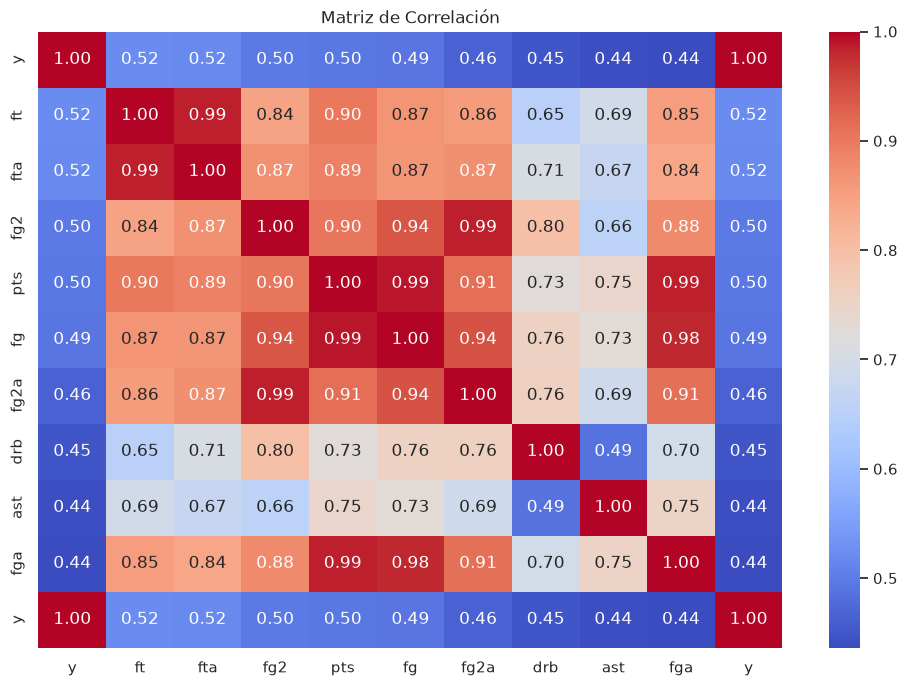

In [5]:
# Matriz de correlación de las 10 variables más importantes
# (Excluimos columnas de texto para que no falle)
df_numeric = df_clean.select_dtypes(include=[np.number])

# Calcular correlación con el target
correlaciones = df_numeric.corr()['y'].sort_values(ascending=False)
print("Top 10 correlaciones con el Target:")
print(correlaciones.head(10))

# Heatmap de correlación de las top 10 variables
top_vars = correlaciones.head(10).index.tolist() + ['y']
plt.figure(figsize=(12, 8))
sns.heatmap(df_numeric[top_vars].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación')
plt.show()

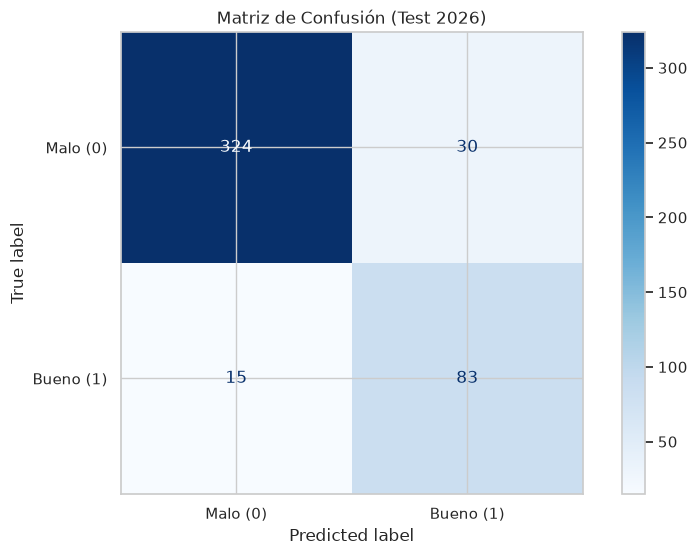

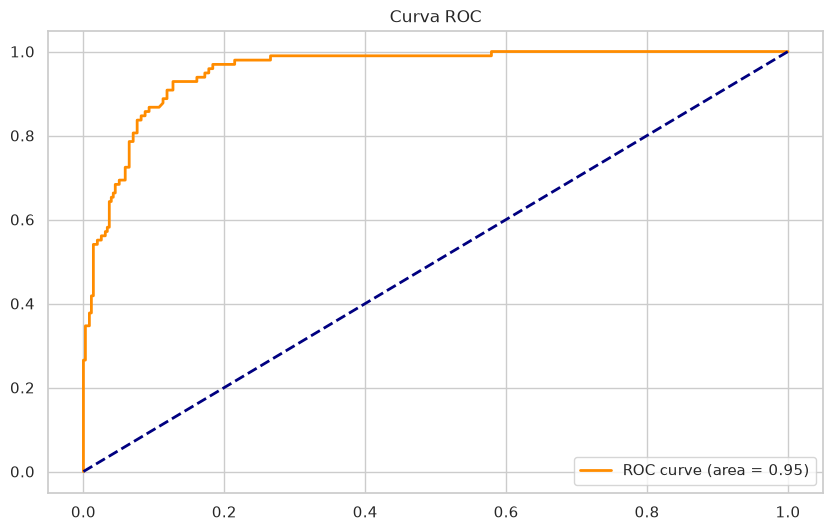

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# 1. Cargar el modelo
pipeline = joblib.load("../models/classifier_pipeline.joblib")

# 2. Separar los datos de 2026
test_mask = df_clean['season'] == 2026
X_test = df_clean[test_mask].drop(columns=['player_id', 'season', 'team', 'y', 'kind', 'pos'], errors='ignore')
y_test = df_clean[test_mask]['y']

# Nota: El pipeline espera 'pos', así que la agregamos de vuelta
X_test['pos'] = df_clean[test_mask]['pos']

# 3. Predecir
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

# 4. Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Malo (0)', 'Bueno (1)'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión (Test 2026)')
plt.show()

# 5. Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

/tmp/ipykernel_11962/3480527510.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importancia, x='Importancia', y='Variable', palette='viridis')


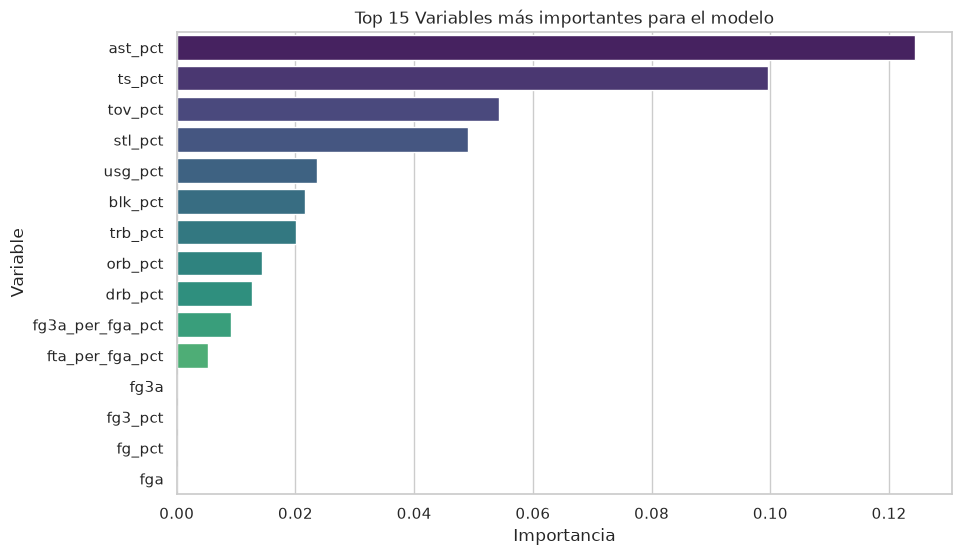

In [7]:
from sklearn.inspection import permutation_importance

# Calcular importancia de permutación (funciona para cualquier modelo)
result = permutation_importance(pipeline, X_test, y_test, n_repeats=10, random_state=42, scoring='accuracy')

# Organizar en un DataFrame
importancia = pd.DataFrame({
    'Variable': X_test.columns,
    'Importancia': result.importances_mean
}).sort_values(by='Importancia', ascending=False).head(15)

# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(data=importancia, x='Importancia', y='Variable', palette='viridis')
plt.title('Top 15 Variables más importantes para el modelo')
plt.show()